# Dice Game Simulator

I simulate five simple dice games and check whether the simulated averages match the expected values (EV) I calculated by hand. For each game I also compute a 95% confidence interval to see whether the difference between simulation and theory is just normal randomness.

## The games and their expected values
Before writing any code, I calculated the expected value of each game by hand.

| # | Game | Expected value (by hand) |
|---|---|---|
| 1 | Roll one die, win its value in € | $\frac{1+2+3+4+5+6}{6} = 3.5$ |
| 2 | Roll one die, you may re-roll once (you must keep the second result) | Re-roll on 1–3: $\frac{3}{6}\cdot 3.5 + \frac{4+5+6}{6} = 4.25$ |
| 3 | Pay €1, win €5 if the sum of two dice is 7 (net result) | $4\cdot\frac{1}{6} - 1\cdot\frac{5}{6} = -\frac{1}{6} \approx -0.167$ |
| 4 | Roll two dice, win the larger value | $P(\max = k) = \frac{2k-1}{36} \Rightarrow \sum_{k=1}^{6} k\,\frac{2k-1}{36} = \frac{161}{36} \approx 4.472$ |
| 5 | Roll until a six appears: how many rolls on average? | Geometric distribution with $p = \frac{1}{6}$: $E = \frac{1}{p} = 6$ |

## 1. Rolling a die
A quick test of the random number generator: ten rolls of a die.

In [10]:
import random as r
import statistics as st
from math import sqrt

for i in range(10):
    print(r.randint(1,6))



1
6
5
5
2
3
5
3
2
6


Wrapping the die roll in a function so every game can reuse it.

In [11]:
def dice():
    return r.randint(1,6)
    
dice()

4

## 2. Games, simulation and metrics
The code is split into three parts:
- **Game functions** play a game once and return the result.
- **`simulation`** plays a game many times and collects all results in a list.
- **`metrics`** summarises the results: mean, standard deviation and a 95% confidence interval (mean ± 1.96 × standard error).

In [12]:
def game_1():
    return dice()

def game_2():
    first_roll = dice()
    if first_roll <= 3:
        return dice()
    else:
        return first_roll
    
def game_3():
    first_dice = dice()
    second_dice = dice()
    if first_dice + second_dice == 7:
        return 4
    else:
        return -1
    
def game_4():
    first_dice = dice()
    second_dice = dice()
    return max(first_dice,second_dice)

def game_5():
    i = 1
    while dice() != 6:
        i += 1
    return i



def simulation(game,times):
    results = []
    for i in range(times):
        results.append(game())
    return results


def metrics(data):
    mean = st.mean(data)
    standard_deviation = st.stdev(data)
    standard_error = standard_deviation / sqrt(len(data))
    lower_bound = mean - (1.96*standard_error)
    upper_bound = mean + (1.96*standard_error)
    return  mean, standard_deviation, lower_bound, upper_bound




**Observations:** The simulated averages are never exactly equal to the expected value, because every simulation is random. With more games the average moves closer to the EV: with 100 games it can be off by a few tenths, with 1,000,000 games only by a few thousandths.

## Results table
Theoretical vs simulated expected value for each game (100,000 games each). In this run the theoretical value falls inside the 95% confidence interval for every game. Since it is a 95% interval, about 1 run in 20 can still miss for a single game just by chance.

In [13]:

games = [(game_1, 'Single die', 3.5), (game_2, 'One re-roll allowed', 4.25), (game_3, 'Bet on seven (net)', -1/6), (game_4, 'Max of two dice', 161/36), (game_5, "Rolls until a six", 6)]

for game,name,theoretical in games:
    results = simulation(game,100000)
    result_simulation, std, low_bound, up_bound = metrics(results)
    print(f"Name: {name} || Theoretical: {round(theoretical,4)} || Simulation: {round(result_simulation,4)} || Difference: {round(result_simulation - theoretical,4)} || 95% CI: [{round(low_bound,4), round(up_bound,4)}] || Inside: {up_bound >= theoretical >= low_bound}")
    


Name: Single die || Theoretical: 3.5 || Simulation: 3.4993 || Difference: -0.0007 || 95% CI: [(3.4887, 3.5099)] || Inside: True
Name: One re-roll allowed || Theoretical: 4.25 || Simulation: 4.2537 || Difference: 0.0037 || 95% CI: [(4.2442, 4.2632)] || Inside: True
Name: Bet on seven (net) || Theoretical: -0.1667 || Simulation: -0.1732 || Difference: -0.0065 || 95% CI: [(-0.1847, -0.1617)] || Inside: True
Name: Max of two dice || Theoretical: 4.4722 || Simulation: 4.4692 || Difference: -0.003 || 95% CI: [(4.4605, 4.4779)] || Inside: True
Name: Rolls until a six || Theoretical: 6 || Simulation: 5.9924 || Difference: -0.0076 || 95% CI: [(5.9586, 6.0262)] || Inside: True


## 3. Charts

### Convergence
The running average after each game. It jumps around at first and then settles on the expected value (law of large numbers). "Rolls until a six" fluctuates more and for longer because its results are much more spread out.

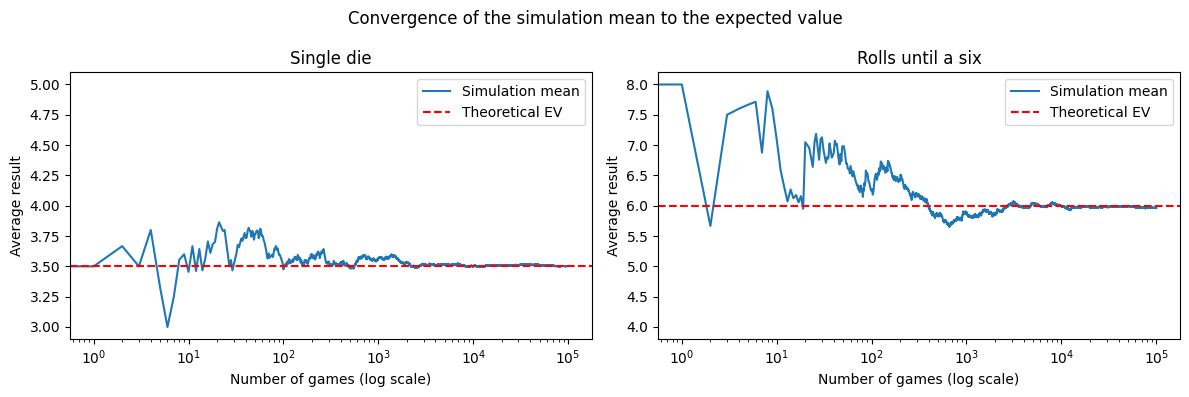

In [14]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

for ax, (game, name, theoretical) in zip(axes, [games[0], games[4]]):
    results = simulation(game, 100000)
    running_means = np.cumsum(results) / np.arange(1, len(results) + 1)
    ax.plot(running_means, label="Simulation mean")
    ax.axhline(theoretical, color="red", linestyle="--", label="Theoretical EV")
    ax.set_xscale("log")
    ax.set_xlabel("Number of games (log scale)")
    ax.set_ylabel("Average result")
    ax.set_title(name)
    ax.legend()

fig.suptitle("Convergence of the simulation mean to the expected value")
plt.tight_layout()
plt.savefig("convergence.png", dpi=150)
plt.show()

### Simulation vs theory with 95% confidence intervals
The difference between the simulated average and the expected value for every game, with its 95% confidence interval. In this run every interval crosses zero, so all differences are explained by normal randomness. "Rolls until a six" has the widest interval because its results are the most spread out.

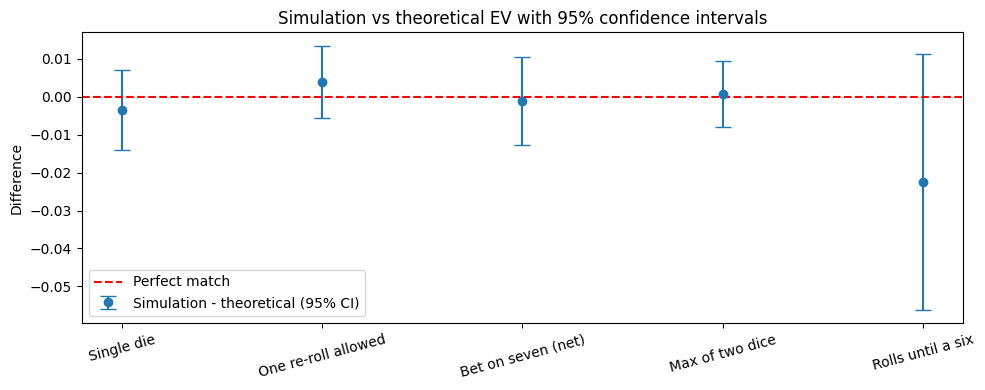

In [15]:
names = []
differences = []
errors = []

for game, name, theoretical in games:
    results = simulation(game, 100000)
    result_simulation, std, low_bound, up_bound = metrics(results)
    names.append(name)
    differences.append(result_simulation - theoretical)
    errors.append((up_bound - low_bound) / 2)

plt.figure(figsize=(10, 4))
plt.errorbar(names, differences, yerr=errors, fmt="o", capsize=6, label="Simulation - theoretical (95% CI)")
plt.axhline(0, color="red", linestyle="--", label="Perfect match")
plt.ylabel("Difference")
plt.title("Simulation vs theoretical EV with 95% confidence intervals")
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.savefig("difference_ci.png", dpi=150)
plt.show()

### Distribution of results
How often each result appears in every game. For "Max of two dice" the simulated frequencies match the theoretical probabilities $(2k-1)/36$. "Rolls until a six" follows a geometric distribution: one roll is the most common result, even though the average is six.

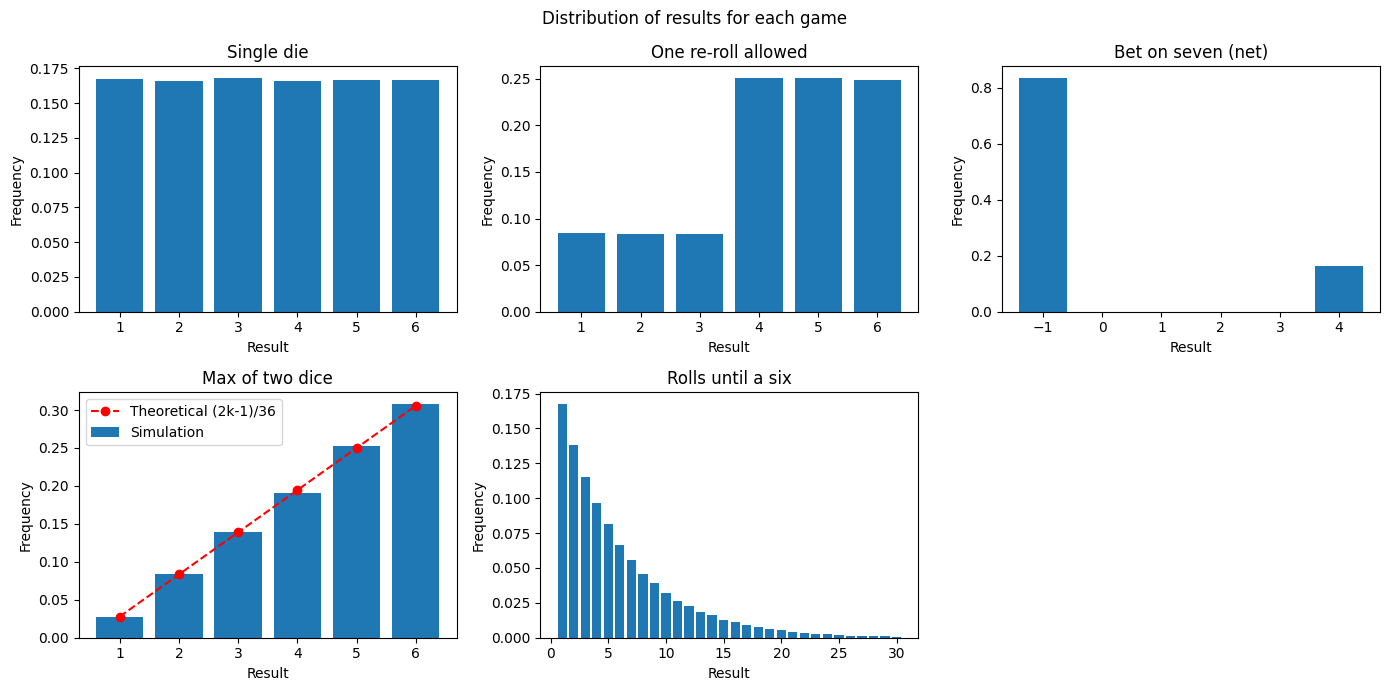

In [16]:
from collections import Counter

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for ax, (game, name, theoretical) in zip(axes, games):
    results = simulation(game, 100000)
    counts = Counter(results)
    values = sorted(counts)
    if name == "Rolls until a six":
        values = [v for v in values if v <= 30]
    frequencies = [counts[v] / len(results) for v in values]
    ax.bar(values, frequencies, label="Simulation")
    if name == "Max of two dice":
        exact = [(2 * k - 1) / 36 for k in range(1, 7)]
        ax.plot(range(1, 7), exact, "ro--", label="Theoretical (2k-1)/36")
        ax.legend()
    ax.set_title(name)
    ax.set_xlabel("Result")
    ax.set_ylabel("Frequency")

axes[5].axis("off")
fig.suptitle("Distribution of results for each game")
plt.tight_layout()
plt.savefig("distributions.png", dpi=150)
plt.show()

### Confidence interval width
The width of the 95% confidence interval for different numbers of games. Ten times more games makes the interval about $\sqrt{10} \approx 3.2$ times narrower, because the standard error falls with $\sqrt{n}$.

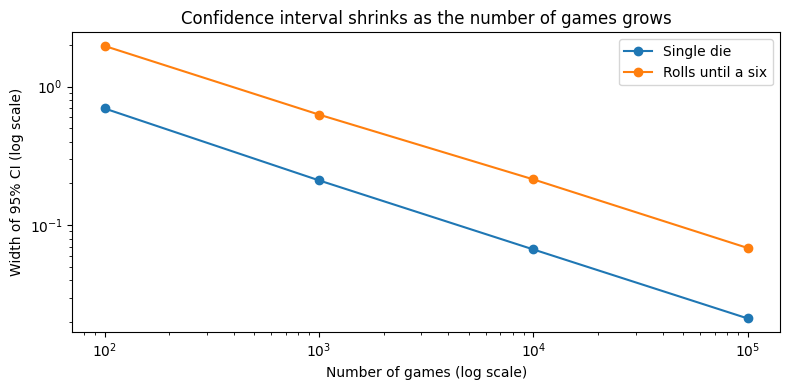

In [17]:
sample_sizes = [100, 1000, 10000, 100000]

plt.figure(figsize=(8, 4))

for game, name, theoretical in [games[0], games[4]]:
    widths = []
    for n in sample_sizes:
        results = simulation(game, n)
        result_simulation, std, low_bound, up_bound = metrics(results)
        widths.append(up_bound - low_bound)
    plt.plot(sample_sizes, widths, "o-", label=name)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of games (log scale)")
plt.ylabel("Width of 95% CI (log scale)")
plt.title("Confidence interval shrinks as the number of games grows")
plt.legend()
plt.tight_layout()
plt.savefig("ci_width.png", dpi=150)
plt.show()